<a href="https://colab.research.google.com/github/ZiyuCao421/26-CP5046-SIN-CAM-TR3-ICT-Project-1-Analysis-and-Design/blob/main/V3/notebooks/04_feature_set_evaluation_and_visualisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# V3 — Stage 4: Feature-Set Evaluation and Visualisation

This Colab notebook evaluates the provisional feature sets produced by Stage 3. It rebuilds the Stage-1 complete-case cohort, recreates the fixed split, evaluates the unchanged Dummy, RBF SVC and Random Forest models, and writes aggregate metrics and figures. Raw rows, predictions, labels and source filenames are never written.

The selected champion is **provisional**: it is the best feature set under this one held-out split, not proof of generalisation to new devices, sessions or participants.

In [1]:
# Environment: no edit needed
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


In [2]:
# =============================================================================
# SINGLE EDITABLE CONFIGURATION BLOCK
# Edit only this cell after mounting Google Drive.
# =============================================================================
RAW_DATA_DIR = '/content/drive/MyDrive/CP5046_Mouse_Dynamics'
FILE_PATTERN = '*.csv'
LABEL_COLUMN = 'label'
STAGE1_OUTPUT_DIR = '/content/drive/MyDrive/CP5046_Mouse_Dynamics/V3'
STAGE3_OUTPUT_DIR = '/content/drive/MyDrive/CP5046_Mouse_Dynamics/V3/stage3_output'
OUTPUT_DIR = '/content/drive/MyDrive/CP5046_Mouse_Dynamics/V3/stage4_output'
MIN_CLASS_COUNT = 5
RANDOM_STATE = 42
TEST_SIZE = 0.20
SAVE_FIGURES = True
FIGURE_DPI = 150


## Inputs and decision rule

Required Stage-1 files are `feature_inventory.csv` and `run_metadata.json`; required Stage-3 file is `feature_set_definitions.json`. Every set must be marked `provisional / not yet evaluated` and contain at least two features.

The primary measure is macro F1. The provisional champion set is ranked by: mean macro F1 of RBF SVC and Random Forest (descending), then the lower of their two macro F1 values (descending), then fewer features, then set name. DummyClassifier is a baseline only and never determines the champion. Accuracy, macro precision and macro recall are secondary diagnostics.

In [3]:
from google.colab import drive
# 卸载可能存在的旧挂载点以避免冲突
!google-colab-unmount 2>/dev/null || true
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [4]:
from pathlib import Path

print(Path("/content/drive/MyDrive").exists())
print([p.name for p in Path("/content/drive/MyDrive").iterdir()])

True
['Colab Notebooks', 'Week3Prac.ipynb', 'Week4Prac.ipynb', 'Untitled0.ipynb', 'paper_rag.ipynb', 'paper_rag (1).ipynb', 'paper_rag', 'test_LLM_ASS2.ipynb', 'Week8Prac.ipynb', 'CP5046_Mouse_Dynamics']


In [5]:
from pathlib import Path

checks = [
    "/content/drive/MyDrive/CP5046_Mouse_Dynamics/V3/feature_inventory.csv",
    "/content/drive/MyDrive/CP5046_Mouse_Dynamics/V3/run_metadata.json",
    "/content/drive/MyDrive/CP5046_Mouse_Dynamics/V3/stage3_output/feature_set_definitions.json",
]

for item in checks:
    path = Path(item)
    print(f"{path.exists()}  |  {item}")

True  |  /content/drive/MyDrive/CP5046_Mouse_Dynamics/V3/feature_inventory.csv
True  |  /content/drive/MyDrive/CP5046_Mouse_Dynamics/V3/run_metadata.json
True  |  /content/drive/MyDrive/CP5046_Mouse_Dynamics/V3/stage3_output/feature_set_definitions.json


In [6]:
RESULTS_VALIDITY = 'only valid after a real Colab run'

def require(condition, message):
    if not condition:
        raise RuntimeError(message)

def sha256_text(value):
    return hashlib.sha256(str(value).encode('utf-8')).hexdigest()

def numeric_values(series):
    values = pd.to_numeric(series, errors='coerce').to_numpy(dtype='float64', na_value=np.nan)
    return values, np.isfinite(values)

s1_dir, s3_dir, raw_dir = map(Path, [STAGE1_OUTPUT_DIR, STAGE3_OUTPUT_DIR, RAW_DATA_DIR])
out_dir = Path(OUTPUT_DIR); fig_dir = out_dir / 'figures'; fig_dir.mkdir(parents=True, exist_ok=True)
required = [s1_dir / 'feature_inventory.csv', s1_dir / 'run_metadata.json', s3_dir / 'feature_set_definitions.json']
require(all(p.is_file() for p in required), 'Missing Stage-1 or Stage-3 aggregate files. Check the three configured directories.')
require(raw_dir.is_dir(), 'RAW_DATA_DIR does not exist. Mount Drive and correct the path.')
inventory = pd.read_csv(s1_dir / 'feature_inventory.csv')
metadata = json.loads((s1_dir / 'run_metadata.json').read_text(encoding='utf-8'))
definitions = json.loads((s3_dir / 'feature_set_definitions.json').read_text(encoding='utf-8'))
require(metadata.get('run_status') == 'completed', 'Stage 1 was not completed.')
require(metadata.get('cohort_mode') == 'complete_case_all_candidates', 'Stage 1 did not use the required shared cohort.')
require(definitions.get('results_validity') in [RESULTS_VALIDITY, 'exploratory / not rankable - only valid after a real Colab run'], 'Stage-3 validity stamp is not recognised.')
require(definitions.get('split_fingerprint') == metadata.get('split_fingerprint'), 'Stage-3 and Stage-1 split fingerprints do not agree.')
candidates = sorted(inventory.loc[inventory['status'].astype(str).eq('candidate'), 'column'].astype(str))
sets = {name: item for name, item in definitions.get('sets', {}).items() if item.get('status') == 'provisional / not yet evaluated' and len(item.get('features', [])) >= 2}
require(candidates and sets, 'No valid Stage-1 candidates or Stage-3 provisional feature sets were found.')
invalid_features = sorted({f for item in sets.values() for f in item['features'] if f not in candidates})
require(not invalid_features, f'Stage-3 set definitions include non-candidate features: {invalid_features}')
print('Sets to evaluate:', {k: v['features'] for k, v in sets.items()})


Sets to evaluate: {'FS1_consensus_compact': ['max_y', 'min_t', 'min_x', 'VV2', 'VV0', 'min_hv'], 'FS2_svc_diverse': ['avg_t', 'max_y', 'min_x', 'VV2', 'min_hv', 'VV0'], 'FS3_random_forest_diverse': ['min_y', 'VV0', 'VV2', 'min_hv', 'min_t', 'min_x']}


In [7]:
# Rebuild the exact Stage-1 complete-case cohort and its fixed split.
raw_files = sorted(p for p in raw_dir.glob(FILE_PATTERN) if p.is_file())
require(raw_files, 'No raw CSV files found in RAW_DATA_DIR.')
frames = []
for path in raw_files:
    frame = pd.read_csv(path)
    if LABEL_COLUMN in frame.columns:
        frames.append(frame)
require(frames, 'No raw CSV with the configured label column was found.')
raw = pd.concat(frames, ignore_index=True, sort=False)
missing = [c for c in candidates if c not in raw.columns]
require(not missing, f'Cannot reproduce the Stage-1 cohort: missing candidate columns {missing}')
numeric = pd.DataFrame(index=raw.index)
complete = pd.Series(True, index=raw.index)
for column in candidates:
    values, finite = numeric_values(raw[column])
    numeric[column] = values
    complete &= finite
label_ok = raw[LABEL_COLUMN].notna()
kept = raw.loc[label_ok, LABEL_COLUMN].value_counts()
kept = kept[kept >= MIN_CLASS_COUNT].index
mask = label_ok & raw[LABEL_COLUMN].isin(kept) & complete
cohort = numeric.loc[mask, candidates].reset_index(drop=True)
y = raw.loc[mask, LABEL_COLUMN].to_numpy()
require(len(cohort) == metadata.get('n_rows_common_cohort'), 'Rebuilt cohort row count differs from Stage 1; stop and correct paths/settings.')
require(pd.Series(y).nunique() == metadata.get('n_classes_common'), 'Rebuilt class count differs from Stage 1.')
positions = np.arange(len(cohort))
train_pos, test_pos = train_test_split(positions, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
payload = json.dumps({'n_rows_common_cohort': len(cohort), 'test_size': TEST_SIZE, 'random_state': RANDOM_STATE, 'train': sorted(map(int, train_pos)), 'test': sorted(map(int, test_pos))}, sort_keys=True)
fingerprint = 'sha256:' + sha256_text(payload)[:32]
require(fingerprint == metadata.get('split_fingerprint'), 'Recreated split fingerprint differs from Stage 1; do not evaluate feature sets.')
print(f'Common cohort: {len(cohort)} rows, {pd.Series(y).nunique()} classes; split: {len(train_pos)} train / {len(test_pos)} test')


Common cohort: 2002 rows, 9 classes; split: 1601 train / 401 test


In [8]:
# Evaluate every candidate set with unchanged models and the one shared split.
def models():
    return {
        'DummyClassifier_most_frequent': DummyClassifier(strategy='most_frequent'),
        'RBF_SVC_scaled': Pipeline([('scaler', StandardScaler()), ('model', SVC(kernel='rbf', C=1.0, gamma='scale', class_weight='balanced'))]),
        'RandomForest_balanced': RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced'),
    }

rows, failures, matrices = [], [], {}
for set_name, definition in sets.items():
    features = definition['features']
    X_train, X_test = cohort.loc[train_pos, features], cohort.loc[test_pos, features]
    for model_name, model in models().items():
        try:
            model.fit(X_train, y[train_pos])
            predicted = model.predict(X_test)
            rows.append({'feature_set': set_name, 'n_features': len(features), 'model': model_name, 'accuracy': accuracy_score(y[test_pos], predicted), 'macro_precision': precision_score(y[test_pos], predicted, average='macro', zero_division=0), 'macro_recall': recall_score(y[test_pos], predicted, average='macro', zero_division=0), 'macro_f1': f1_score(y[test_pos], predicted, average='macro', zero_division=0), 'n_train_common': len(train_pos), 'n_test_common': len(test_pos), 'n_classes_common': pd.Series(y).nunique(), 'split_fingerprint': fingerprint, 'results_validity': RESULTS_VALIDITY})
            if model_name != 'DummyClassifier_most_frequent':
                matrices[(set_name, model_name)] = confusion_matrix(y[test_pos], predicted)
        except Exception as exc:
            failures.append({'feature_set': set_name, 'model': model_name, 'error_type': type(exc).__name__, 'error_message': str(exc), 'results_validity': RESULTS_VALIDITY})
metrics = pd.DataFrame(rows); failure_table = pd.DataFrame(failures)
require(not metrics.empty, 'Every model evaluation failed; inspect feature_set_failures.csv.')
metrics.to_csv(out_dir / 'feature_set_metrics.csv', index=False)
failure_table.to_csv(out_dir / 'feature_set_failures.csv', index=False)
real = metrics[metrics['model'] != 'DummyClassifier_most_frequent'].pivot(index='feature_set', columns='model', values='macro_f1')
ranking = real.assign(mean_macro_f1_real_models=real.mean(axis=1), min_macro_f1_real_models=real.min(axis=1), n_features=pd.Series({name: len(item['features']) for name, item in sets.items()})).reset_index()
ranking = ranking.sort_values(['mean_macro_f1_real_models', 'min_macro_f1_real_models', 'n_features', 'feature_set'], ascending=[False, False, True, True]).reset_index(drop=True)
ranking.insert(0, 'rank', np.arange(1, len(ranking) + 1)); ranking['results_validity'] = RESULTS_VALIDITY; ranking['split_fingerprint'] = fingerprint
ranking.to_csv(out_dir / 'feature_set_ranking.csv', index=False)
champion = ranking.iloc[0]['feature_set']
print('Provisional champion feature set:', champion)
display(ranking)


Provisional champion feature set: FS3_random_forest_diverse


model,rank,feature_set,RBF_SVC_scaled,RandomForest_balanced,mean_macro_f1_real_models,min_macro_f1_real_models,n_features,results_validity,split_fingerprint
0,1,FS3_random_forest_diverse,0.486759,0.806632,0.646695,0.486759,6,only valid after a real Colab run,sha256:297284c375de6cb3535fbd2268907915
1,2,FS2_svc_diverse,0.487818,0.795278,0.641548,0.487818,6,only valid after a real Colab run,sha256:297284c375de6cb3535fbd2268907915
2,3,FS1_consensus_compact,0.484344,0.789811,0.637078,0.484344,6,only valid after a real Colab run,sha256:297284c375de6cb3535fbd2268907915


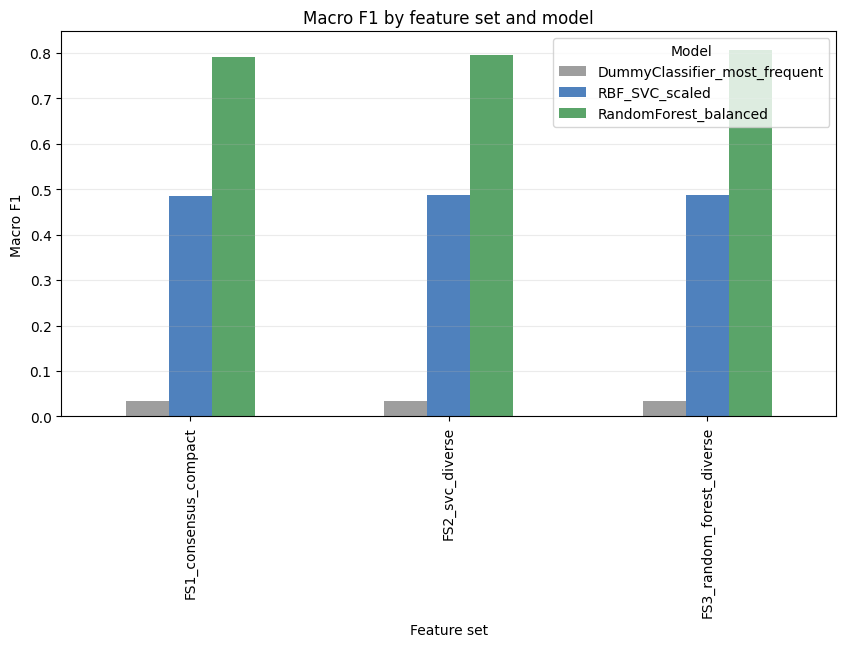

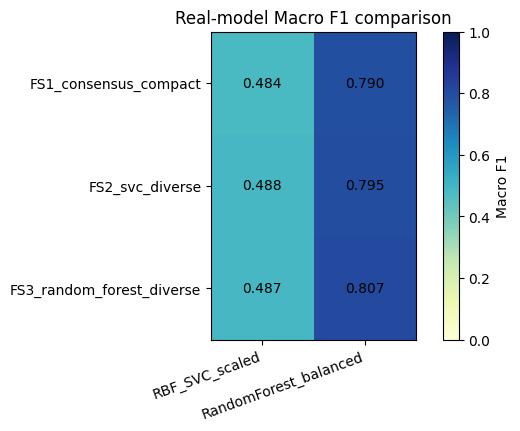

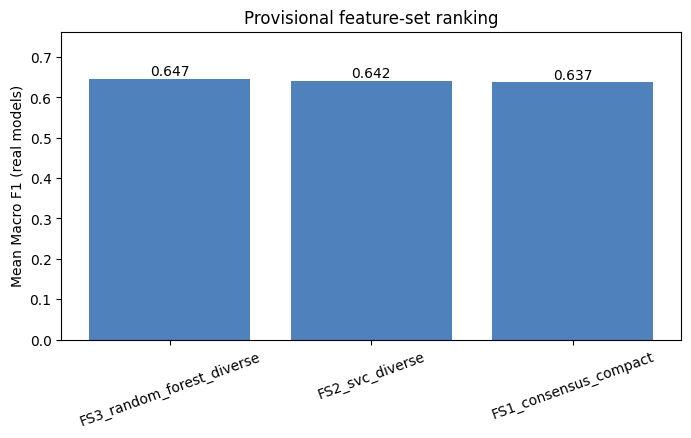

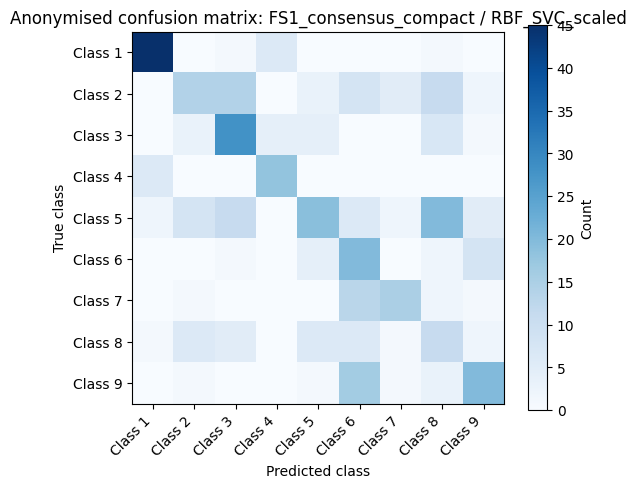

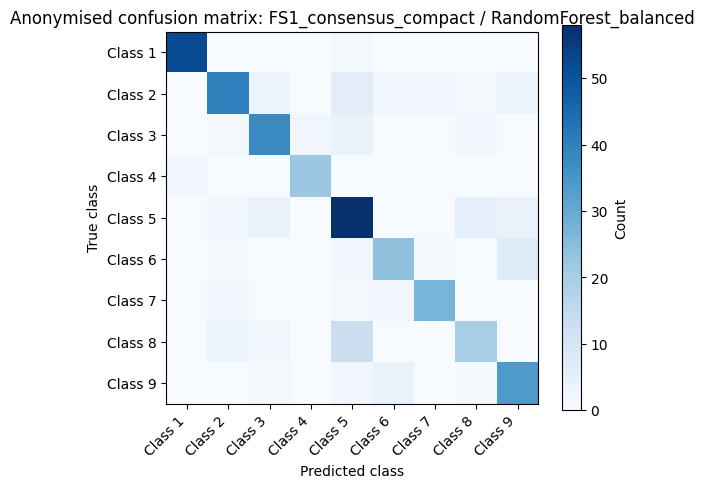

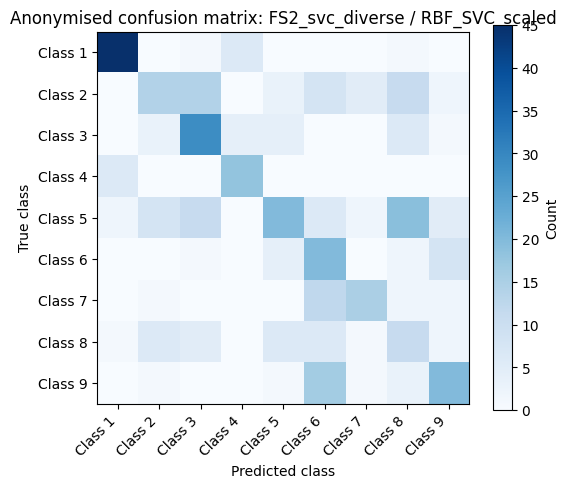

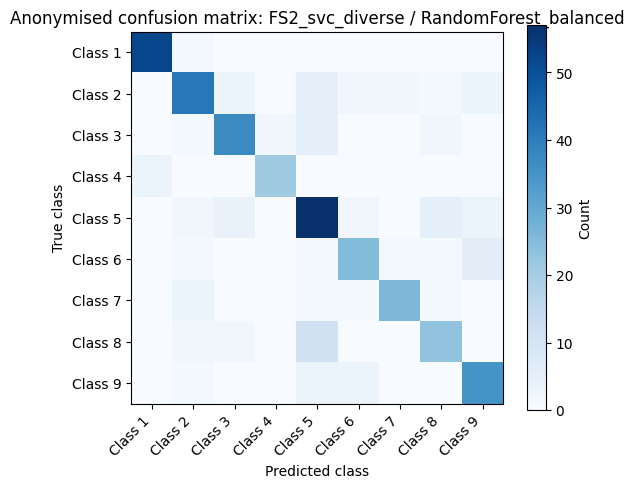

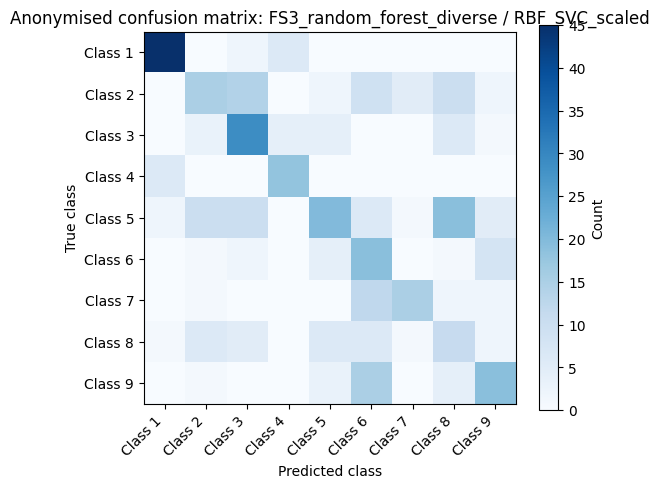

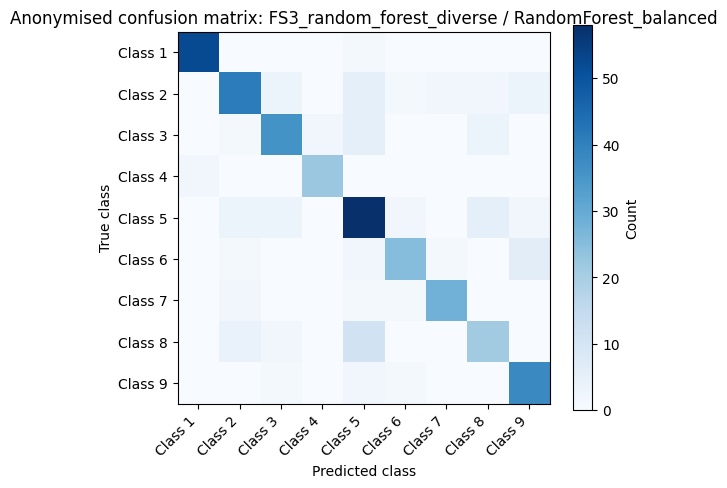

In [9]:
# Visual analysis: aggregate metrics only; confusion-matrix labels are anonymised.
def save(fig, name):
    if SAVE_FIGURES:
        fig.savefig(fig_dir / name, dpi=FIGURE_DPI, bbox_inches='tight')
    plt.show(); plt.close(fig)

pivot = metrics.pivot(index='feature_set', columns='model', values='macro_f1')
fig, ax = plt.subplots(figsize=(10, 5)); pivot.plot(kind='bar', ax=ax, color=['#9e9e9e', '#4f81bd', '#5aa469'])
ax.set_title('Macro F1 by feature set and model'); ax.set_ylabel('Macro F1'); ax.set_xlabel('Feature set'); ax.legend(title='Model'); ax.grid(axis='y', alpha=.25); save(fig, 'macro_f1_by_feature_set_and_model.png')

fig, ax = plt.subplots(figsize=(7, 4)); image = ax.imshow(real.to_numpy(), cmap='YlGnBu', vmin=0, vmax=1)
ax.set_xticks(range(len(real.columns)), real.columns, rotation=20, ha='right'); ax.set_yticks(range(len(real.index)), real.index)
for i in range(real.shape[0]):
    for j in range(real.shape[1]): ax.text(j, i, f'{real.iloc[i, j]:.3f}', ha='center', va='center')
fig.colorbar(image, ax=ax, label='Macro F1'); ax.set_title('Real-model Macro F1 comparison'); save(fig, 'macro_f1_heatmap_real_models.png')

fig, ax = plt.subplots(figsize=(8, 4)); ax.bar(ranking['feature_set'], ranking['mean_macro_f1_real_models'], color='#4f81bd')
for i, value in enumerate(ranking['mean_macro_f1_real_models']): ax.text(i, value, f'{value:.3f}', ha='center', va='bottom')
ax.set_ylim(0, min(1, max(.1, ranking['mean_macro_f1_real_models'].max() * 1.18))); ax.set_ylabel('Mean Macro F1 (real models)'); ax.set_title('Provisional feature-set ranking'); ax.tick_params(axis='x', rotation=20); save(fig, 'provisional_feature_set_ranking.png')

class_labels = [f'Class {i + 1}' for i in range(pd.Series(y).nunique())]
for (set_name, model_name), matrix in matrices.items():
    fig, ax = plt.subplots(figsize=(6, 5)); image = ax.imshow(matrix, cmap='Blues')
    ax.set_xticks(range(len(class_labels)), class_labels, rotation=45, ha='right'); ax.set_yticks(range(len(class_labels)), class_labels)
    ax.set_xlabel('Predicted class'); ax.set_ylabel('True class'); ax.set_title(f'Anonymised confusion matrix: {set_name} / {model_name}')
    fig.colorbar(image, ax=ax, label='Count'); save(fig, f'confusion_{set_name}_{model_name}.png')


In [10]:
manifest = {
    'results_validity': RESULTS_VALIDITY,
    'stage': 'V3 stage 4 - feature-set evaluation and visualisation',
    'configuration': {'RAW_DATA_DIR': '<withheld>', 'STAGE1_OUTPUT_DIR': '<withheld>', 'STAGE3_OUTPUT_DIR': '<withheld>', 'OUTPUT_DIR': '<withheld>', 'MIN_CLASS_COUNT': MIN_CLASS_COUNT, 'RANDOM_STATE': RANDOM_STATE, 'TEST_SIZE': TEST_SIZE},
    'cohort': {'n_rows_common_cohort': len(cohort), 'n_train_common': len(train_pos), 'n_test_common': len(test_pos), 'n_classes_common': int(pd.Series(y).nunique()), 'split_fingerprint': fingerprint},
    'feature_sets': {name: item['features'] for name, item in sets.items()},
    'provisional_champion_feature_set': champion,
    'champion_rule': 'mean Macro F1 of RBF SVC and Random Forest, then lower real-model Macro F1, then fewer features, then set name',
    'limitations': ['The champion is provisional and selected using one held-out split.', 'No raw rows, predictions, label values or source filenames were written.', 'Use repeated, group-aware or external evaluation before any final generalisation claim.'],
    'figures': sorted(p.name for p in fig_dir.glob('*.png'))
}
(out_dir / 'feature_set_evaluation_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
report = f'''# V3 Stage 4 — Feature-Set Evaluation Report

**Validity:** {RESULTS_VALIDITY}

The three Stage-3 provisional sets were evaluated with one reconstructed Stage-1 cohort and the same fixed stratified split. The primary metric is Macro F1. The provisional champion is **{champion}**; this is a within-split comparison, not a generalisation claim.

## Outputs

- `feature_set_metrics.csv`: all model/set metrics.
- `feature_set_ranking.csv`: transparent champion ranking.
- `feature_set_failures.csv`: any failed evaluation.
- `figures/`: Macro-F1 comparisons and anonymised confusion matrices.

## Limitation

A final conclusion requires repeated, group-aware or external validation because this ranking reuses a single held-out split.
'''
(out_dir / '04_feature_set_evaluation_report.md').write_text(report, encoding='utf-8')
print('Saved aggregate Stage-4 outputs to:', out_dir)
print('Champion is provisional; inspect the ranking and figures before reporting it.')


Saved aggregate Stage-4 outputs to: /content/drive/MyDrive/CP5046_Mouse_Dynamics/V3/stage4_output
Champion is provisional; inspect the ranking and figures before reporting it.


## Files to retain

Keep the complete output directory, especially `feature_set_metrics.csv`, `feature_set_ranking.csv`, `feature_set_evaluation_manifest.json`, `04_feature_set_evaluation_report.md`, and `figures/`. Do not upload or commit the source CSV files.